# CNN Feature Visualization, Parameter Audit and Critical Analysis
**Deep Learning and Computer Vision, Practical Laboratory Assignment**

| Student Name | Registration / Roll No. | Course / Section | Submission Date |
|---|---|---|---|
| Yahya Tamimy | FA23-BAI-020 | CV | 26 November |

---
## Contents
1. [Results at a glance](#results)
2. [Part I: Filter pipeline and 5 x 4 grid](#part1)
   * I.1 Input image, I.2 Kernels, I.3 Run the four stages, I.4 The 5 x 4 grid, I.5 Statistics table
3. [Part II: Architecture comparison and parameter audit](#part2)
   * II.1 Hand calculation, II.2 Model summaries, II.3 Audit table
4. [Part III: Evidence for the viva questions](#part3)
   * Q1 ReLU blackout, Q2 pooling, Q3 parameters and receptive field, Q4 order of operations, Q5 filter collapse

**How to run:** Part I cells share variables, so run them from top to bottom. Part II and every question cell in Part III are self-contained and can be run alone. The input image `building.png` (Figure 2 of the assignment sheet) must sit in the same folder as this notebook. If it is missing, a synthetic window-grid image is used.

**Written answers** to Questions 1 to 5 are in the separate file `CNN_Lab_Viva_Answers.pdf`.

<a id="results"></a>
## Results at a glance

| Item | Result |
|---|---|
| Input image | Grayscale, 688 x 384, pixel values scaled to 0..1 |
| Filters | Horizontal edge, Vertical edge, Sharpen, Gaussian blur, Emboss (all 3x3) |
| Stages | A raw convolution, B ReLU, C max pool 2x2, D average pool 2x2 |
| Grid | 5 rows x 4 columns, same intensity range inside each row, colorbar on every panel |
| Model A (3x3, max pool) | Manual 710 = Code 710 |
| Model B (5x5, avg pool) | Manual 1750 = Code 1750 |
| Parameter increase A to B | 1040 more parameters, **146.48%** |
| Receptive field of one 5x5 layer | Two stacked 3x3 layers (saves 28% of weights when channel counts are equal) |
| ReLU then MaxPool vs MaxPool then ReLU | Identical output (proved and checked on all 5 maps) |
| Filter collapse test | Identical init: similarity 0.948. Learning rate 30: 5 of 5 filters dead. Fix: He init, lr 0.05, Leaky ReLU |

Naming note: the sheet calls kernel 1 a "horizontal edge detector (Sobel-X/Prewitt)". A kernel that responds to horizontal edges subtracts the row above from the row below, which is the Sobel-Y pattern in gradient notation. Kernel 1 follows the geometry (it finds horizontal edges) and kernel 2 finds vertical edges.

<a id="part1"></a>
# Part I: Filter pipeline implementation and visualization
**Goal:** pass one image through five 3x3 kernels and record four stages for each (A raw, B ReLU, C max pool, D average pool), then show all 20 maps in one grid.

### I.1 Input image

Image shape: (384, 688) (height x width), min = 0.00, max = 1.00


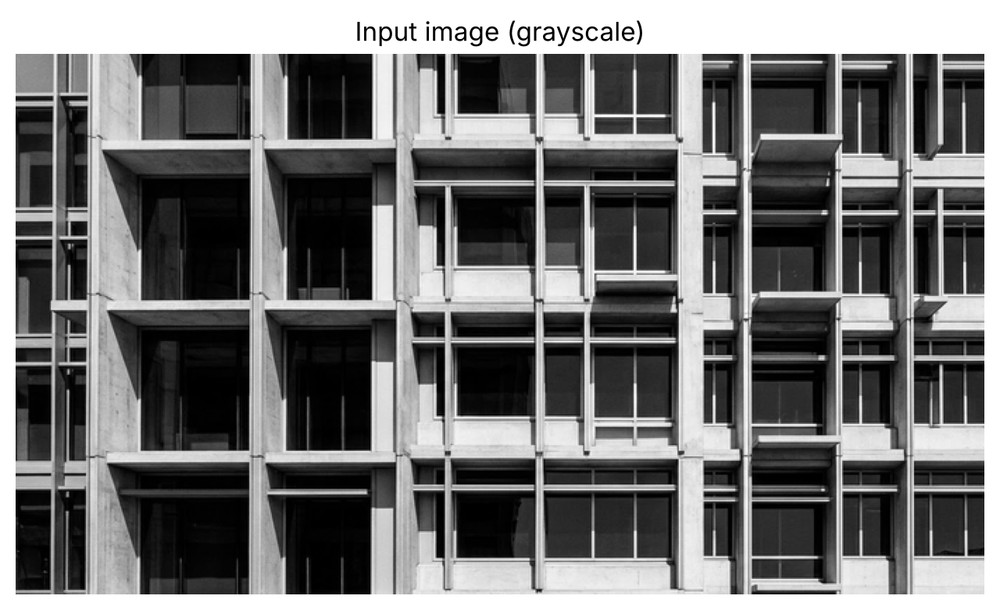

In [ ]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from scipy.signal import correlate2d
from IPython.display import display

IMG_PATH = "building.png"
if os.path.exists(IMG_PATH):
    img = Image.open(IMG_PATH).convert("L").resize((688, 384), Image.LANCZOS)
    img = np.asarray(img, dtype=np.float64) / 255.0
else:  # fallback so the notebook still runs
    img = np.full((384, 688), 0.85)
    for y in range(0, 384, 96): img[y:y+8, :] = 0.95
    for x in range(0, 688, 86): img[:, x:x+8] = 0.95
    for y in range(20, 384, 96):
        for x in range(20, 688, 86): img[y:y+60, x:x+58] = 0.15

print(f"Image shape: {img.shape} (height x width), min = {img.min():.2f}, max = {img.max():.2f}")
plt.figure(figsize=(8, 4.5)); plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.title("Input image (grayscale)"); plt.axis("off"); plt.show()

### I.2 The five 3x3 kernels

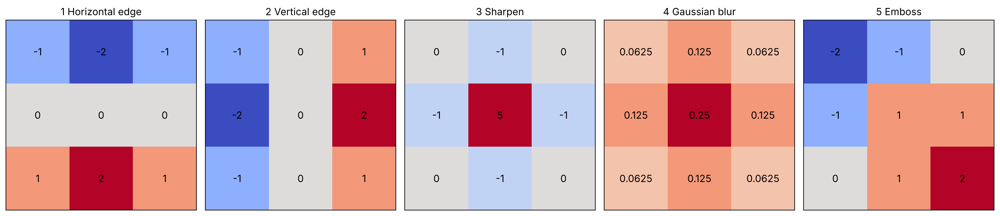

,Sum of weights,What it does
Kernel,,
1 Horizontal edge,0.0,Responds to horizontal edges (row below minus ...
2 Vertical edge,0.0,Responds to vertical edges (right column minus...
3 Sharpen,1.0,Boosts the centre pixel against its 4 neighbours
4 Gaussian blur,1.0,Weighted average of the 3x3 neighbourhood
5 Emboss,1.0,Directional relief effect


In [ ]:
kernels = {
    "1 Horizontal edge": np.array([[-1, -2, -1], [ 0, 0, 0], [ 1, 2, 1]], dtype=float),
    "2 Vertical edge":   np.array([[-1,  0,  1], [-2, 0, 2], [-1, 0, 1]], dtype=float),
    "3 Sharpen":         np.array([[ 0, -1,  0], [-1, 5, -1], [ 0, -1, 0]], dtype=float),
    "4 Gaussian blur":   np.array([[ 1,  2,  1], [ 2, 4, 2], [ 1,  2, 1]], dtype=float) / 16.0,
    "5 Emboss":          np.array([[-2, -1,  0], [-1, 1, 1], [ 0,  1, 2]], dtype=float),
}

fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, (name, k) in zip(axes, kernels.items()):
    ax.imshow(k, cmap="coolwarm", vmin=-np.abs(k).max(), vmax=np.abs(k).max())
    for (i, j), v in np.ndenumerate(k):
        ax.text(j, i, f"{v:.3g}", ha="center", va="center", fontsize=12)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

purpose = ["Responds to horizontal edges (row below minus row above)", "Responds to vertical edges (right column minus left column)",
           "Boosts the centre pixel against its 4 neighbours", "Weighted average of the 3x3 neighbourhood", "Directional relief effect"]
display(pd.DataFrame({"Kernel": list(kernels), "Sum of weights": [round(k.sum(), 3) for k in kernels.values()], "What it does": purpose}).set_index("Kernel"))

### I.3 Run the four stages for every filter

In [ ]:
def conv2d(x, k):
    # CNN convention (cross-correlation), 'same' output size, mirrored borders
    return correlate2d(x, k, mode="same", boundary="symm")

def relu(x):
    return np.maximum(0.0, x)

def pool2x2(x, kind):
    h, w = (x.shape[0] // 2) * 2, (x.shape[1] // 2) * 2
    blocks = x[:h, :w].reshape(h // 2, 2, w // 2, 2)
    return blocks.max(axis=(1, 3)) if kind == "max" else blocks.mean(axis=(1, 3))

results = {}
for name, k in kernels.items():
    A = conv2d(img, k)            # Stage A: raw convolution
    B = relu(A)                   # Stage B: ReLU
    C_ = pool2x2(B, "max")        # Stage C: max pooling, 2x2, stride 2
    D = pool2x2(B, "avg")         # Stage D: average pooling, 2x2, stride 2
    results[name] = (A, B, C_, D)

shape = lambda m: f"{m.shape[1]} x {m.shape[0]}"
display(pd.DataFrame({name: {"A raw": shape(m[0]), "B ReLU": shape(m[1]), "C max pool": shape(m[2]), "D avg pool": shape(m[3])}
                      for name, m in results.items()}).T.rename_axis("Filter (width x height)"))

,A raw,B ReLU,C max pool,D avg pool
Filter (width x height),,,,
1 Horizontal edge,688 x 384,688 x 384,344 x 192,344 x 192
2 Vertical edge,688 x 384,688 x 384,344 x 192,344 x 192
3 Sharpen,688 x 384,688 x 384,344 x 192,344 x 192
4 Gaussian blur,688 x 384,688 x 384,344 x 192,344 x 192
5 Emboss,688 x 384,688 x 384,344 x 192,344 x 192


### I.4 The 5 x 4 comparison grid
Rows are the five filters, columns are Stages A to D. Inside each row all panels use the same intensity range (vmax = largest absolute raw value of that row).
Stage A uses a blue to red scale centred on 0 (blue = negative, red = positive). Stages B, C, D use black to white starting at 0, so a value of 0 is pure black.

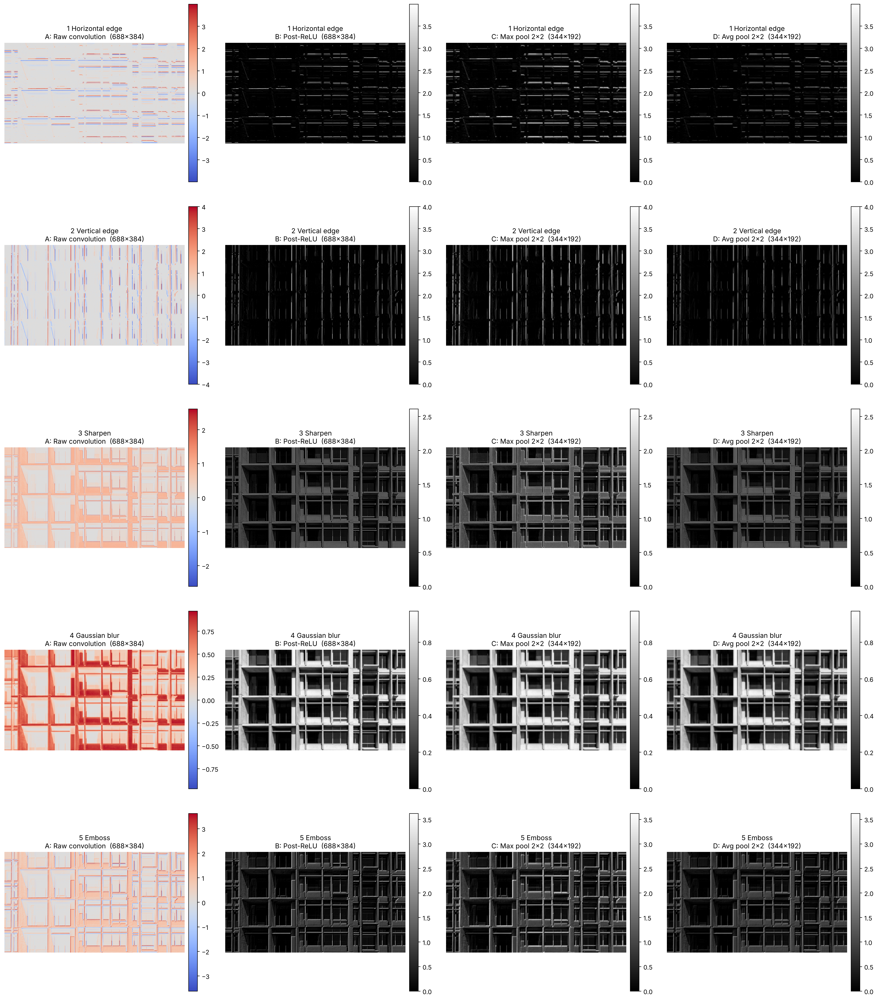

In [ ]:
stage_titles = ["A: Raw convolution", "B: Post-ReLU", "C: Max pool 2x2", "D: Avg pool 2x2"]
fig, axes = plt.subplots(5, 4, figsize=(20, 23))
for r, (name, maps) in enumerate(results.items()):
    vmax = np.abs(maps[0]).max()
    for c, m in enumerate(maps):
        ax = axes[r, c]
        if c == 0: im = ax.imshow(m, cmap="coolwarm", vmin=-vmax, vmax=vmax)
        else:      im = ax.imshow(m, cmap="gray", vmin=0, vmax=vmax)
        ax.set_title(f"{name}\n{stage_titles[c]}  ({m.shape[1]}x{m.shape[0]})", fontsize=11)
        ax.axis("off"); fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
plt.tight_layout()
plt.savefig("cnn_5x4_grid.png", dpi=110, bbox_inches="tight")
plt.show()

### I.5 Numbers behind the grid

In [ ]:
rows = []
for name, (A, B, C_, D) in results.items():
    rows.append({
        "Filter": name,
        "% negative (A)": 100 * (A < -1e-9).mean(),
        "% black after ReLU (B)": 100 * (B == 0).mean(),
        "Peak A": A.max(), "Peak C (max pool)": C_.max(), "Peak D (avg pool)": D.max(),
        "Mean C": C_.mean(), "Mean D": D.mean(),
    })
stats = pd.DataFrame(rows).set_index("Filter").round(3)
display(stats)

,% negative (A),% black after ReLU (B),Peak A,Peak C (max pool),Peak D (avg pool),Mean C,Mean D
Filter,,,,,,,
1 Horizontal edge,42.035,46.055,3.988,3.988,3.150,0.211,0.125
2 Vertical edge,48.419,53.173,3.910,3.910,3.218,0.252,0.157
3 Sharpen,15.921,17.259,2.612,2.612,1.526,0.545,0.392
4 Gaussian blur,0.000,0.268,0.969,0.969,0.951,0.395,0.365
5 Emboss,21.033,21.998,3.620,3.620,3.133,0.642,0.474


**Reading the table.** Max pooling keeps the peak value of the ReLU map unchanged (Peak C equals Peak A for every filter), while average pooling lowers it (Peak D is smaller). The two edge filters have the most pixels that turn black after ReLU, because roughly half of their responses are negative. The blur filter has almost no negative pixels, so ReLU changes it very little.

<a id="part2"></a>
# Part II: Architectural comparison and parameter audit
**Goal:** count the trainable parameters of two small CNNs by hand, then check the counts against `model.summary()`.

Both models take a 32 x 32 x 3 image and use `padding="same"` (padding adds no parameters).
Layout: Conv1 (5 filters) -> ReLU -> Pool -> Conv2 (10 filters) -> ReLU -> Pool -> Global Average Pooling -> Dense(10).

Formula: **Parameters per conv layer = (Kh x Kw x Cin + 1) x Cout**. Dense layer: (inputs + 1) x outputs. ReLU, pooling and Global Average Pooling have 0 parameters.

### II.1 Hand calculation

**Model A (3 x 3 kernels, max pooling)**

| Layer | Working | Parameters |
|---|---|---|
| Conv1 (Cin 3, Cout 5) | (3 x 3 x 3 + 1) x 5 = 28 x 5 | 140 |
| Max pool 2x2 | no weights | 0 |
| Conv2 (Cin 5, Cout 10) | (3 x 3 x 5 + 1) x 10 = 46 x 10 | 460 |
| Max pool 2x2, Global Average Pooling | no weights | 0 |
| Dense (10 in, 10 out) | (10 + 1) x 10 | 110 |
| **Total** | 140 + 460 + 110 | **710** |

**Model B (5 x 5 kernels, average pooling)**

| Layer | Working | Parameters |
|---|---|---|
| Conv1 (Cin 3, Cout 5) | (5 x 5 x 3 + 1) x 5 = 76 x 5 | 380 |
| Avg pool 2x2 | no weights | 0 |
| Conv2 (Cin 5, Cout 10) | (5 x 5 x 5 + 1) x 10 = 126 x 10 | 1260 |
| Avg pool 2x2, Global Average Pooling | no weights | 0 |
| Dense (10 in, 10 out) | (10 + 1) x 10 | 110 |
| **Total** | 380 + 1260 + 110 | **1750** |

### II.2 Build the models and print the framework summaries

In [ ]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import display
from tensorflow import keras
from tensorflow.keras import layers

def conv_params(kh, kw, cin, cout): return (kh * kw * cin + 1) * cout
def dense_params(n_in, n_out):      return (n_in + 1) * n_out

def manual_count(k):
    c1, c2, d = conv_params(k, k, 3, 5), conv_params(k, k, 5, 10), dense_params(10, 10)
    return c1, c2, d, c1 + c2 + d

def build_model(k, pool, name):
    Pool = layers.MaxPooling2D if pool == "max" else layers.AveragePooling2D
    return keras.Sequential([
        keras.Input((32, 32, 3)),
        layers.Conv2D(5, k, padding="same", activation="relu"),
        Pool(2, strides=2),
        layers.Conv2D(10, k, padding="same", activation="relu"),
        Pool(2, strides=2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(10, activation="softmax"),
    ], name=name)

model_a = build_model(3, "max", "Model_A_3x3_MaxPool")
model_b = build_model(5, "avg", "Model_B_5x5_AvgPool")

for model in (model_a, model_b):
    print("=" * 70)
    model.summary(print_fn=lambda line, **kw: print(line))

Model: "Model_A_3x3_MaxPool"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │            

Model: "Model_B_5x5_AvgPool"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 16, 16, 5)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 8, 8, 10)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────

### II.3 Audit table: manual count vs framework output

In [ ]:
audit = pd.DataFrame([
    {"Model": "Model A (Standard)",     "Conv1": "5 filters", "Conv2": "10 filters", "Kernel": "3 x 3", "Pooling": "Max (2x2, stride 2)",
     "Conv1 params": manual_count(3)[0], "Conv2 params": manual_count(3)[1], "Dense params": manual_count(3)[2],
     "Manual count": manual_count(3)[3], "Code output": model_a.count_params()},
    {"Model": "Model B (Large Kernel)", "Conv1": "5 filters", "Conv2": "10 filters", "Kernel": "5 x 5", "Pooling": "Avg (2x2, stride 2)",
     "Conv1 params": manual_count(5)[0], "Conv2 params": manual_count(5)[1], "Dense params": manual_count(5)[2],
     "Manual count": manual_count(5)[3], "Code output": model_b.count_params()},
]).set_index("Model")
audit["Match"] = audit["Manual count"] == audit["Code output"]
display(audit)
assert audit["Match"].all(), "manual count and framework count differ"
print("Manual counts match the framework output for both models.")

,Conv1,Conv2,Kernel,Pooling,Conv1 params,Conv2 params,Dense params,Manual count,Code output,Match
Model,,,,,,,,,,
Model A (Standard),5 filters,10 filters,3 x 3,"Max (2x2, stride 2)",140,460,110,710,710,True
Model B (Large Kernel),5 filters,10 filters,5 x 5,"Avg (2x2, stride 2)",380,1260,110,1750,1750,True


Manual counts match the framework output for both models.


<a id="part3"></a>
# Part III: Evidence for the viva questions
Each cell below is independent. It prints the numbers used in the written answers (`CNN_Lab_Viva_Answers.pdf`).

## Question 1: ReLU blackout, Leaky ReLU and Sigmoid
**What the cell shows:** raw, ReLU, Leaky ReLU (alpha 0.1) and Sigmoid maps for the horizontal and vertical edge filters, the share of black pixels, and one negative pixel worked out by hand.

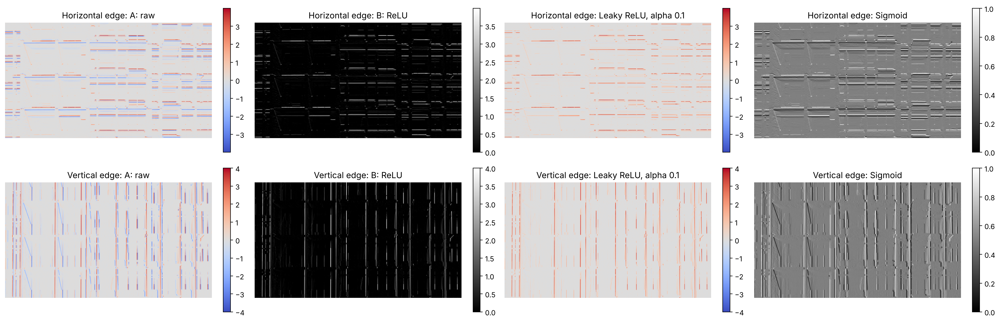

,% negative,% black after ReLU,Sigmoid(0) (flat area),Sigmoid min,Sigmoid max
Filter,,,,,
Horizontal edge,42.035,46.055,0.5,0.026,0.982
Vertical edge,48.419,53.173,0.5,0.018,0.980


Strongest negative horizontal-edge response at row 114, column 574
3x3 pixel patch (top row is bright, bottom row is dark):
[[1.    0.976 1.   ]
 [0.392 0.384 0.396]
 [0.078 0.09  0.051]]


,Value
Raw convolution,-3.643137
ReLU,0.0
Leaky ReLU (0.1),-0.36431372549019614
Sigmoid,0.025503


In [ ]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from scipy.signal import correlate2d
from IPython.display import display

img = np.asarray(Image.open("building.png").convert("L").resize((688, 384), Image.LANCZOS), dtype=float) / 255.0
kh = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float)   # row below minus row above
kv = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float)   # right column minus left column
conv = lambda x, k: correlate2d(x, k, mode="same", boundary="symm")
relu = lambda x: np.maximum(0, x)
leaky = lambda x, a=0.1: np.where(x > 0, x, a * x)
sigmoid = lambda x: 1 / (1 + np.exp(-x))

# --- maps ---
fig, axes = plt.subplots(2, 4, figsize=(20, 6.5))
for r, (name, k) in enumerate([("Horizontal edge", kh), ("Vertical edge", kv)]):
    A = conv(img, k); vmax = np.abs(A).max()
    panels = [("A: raw", A, "coolwarm", -vmax, vmax), ("B: ReLU", relu(A), "gray", 0, vmax),
              ("Leaky ReLU, alpha 0.1", leaky(A), "coolwarm", -vmax, vmax), ("Sigmoid", sigmoid(A), "gray", 0, 1)]
    for c, (t, m, cm, lo, hi) in enumerate(panels):
        im = axes[r, c].imshow(m, cmap=cm, vmin=lo, vmax=hi)
        axes[r, c].set_title(f"{name}: {t}"); axes[r, c].axis("off")
        fig.colorbar(im, ax=axes[r, c], fraction=0.046)
plt.tight_layout(); plt.show()

# --- numbers ---
rows = []
for name, k in [("Horizontal edge", kh), ("Vertical edge", kv)]:
    A = conv(img, k)
    rows.append({"Filter": name, "% negative": 100 * (A < -1e-9).mean(), "% black after ReLU": 100 * (relu(A) == 0).mean(),
                 "Sigmoid(0) (flat area)": sigmoid(0.0), "Sigmoid min": sigmoid(A).min(), "Sigmoid max": sigmoid(A).max()})
display(pd.DataFrame(rows).set_index("Filter").round(3))

# --- one negative pixel by hand ---
pad = np.pad(img, 1, mode="symmetric")
A = conv(img, kh)
inner = np.zeros_like(A, bool); inner[5:-5, 5:-5] = True
i, j = np.unravel_index(np.argmin(np.where(inner, A, np.inf)), A.shape)
patch = pad[i:i+3, j:j+3]; v = np.sum(patch * kh)
print(f"Strongest negative horizontal-edge response at row {i}, column {j}")
print("3x3 pixel patch (top row is bright, bottom row is dark):"); print(np.round(patch, 3))
display(pd.DataFrame({"Value": [v, relu(v), leaky(v), sigmoid(v)]}, index=["Raw convolution", "ReLU", "Leaky ReLU (0.1)", "Sigmoid"]).round(4))

**Takeaway.** About 46% (horizontal) and 53% (vertical) of the pixels are black after ReLU: flat areas plus every edge whose bright side is above (or to the left of) its dark side. Leaky ReLU keeps those edges at one tenth of their strength. Sigmoid has no true zeros, turns flat areas into mid-gray (0.5) and squashes strong responses.

## Question 2: Max pooling vs average pooling
**What the cell shows:** how much of the peak response each pooling keeps for the Edge and Sharpen filters, and a test with dark ink on a white background.

,Peak after ReLU,Peak max pool,Peak avg pool,Avg peak / Max peak,% pixels above half of peak (max),% pixels above half of peak (avg)
Filter,,,,,,
Horizontal edge,3.988,3.988,3.150,0.790,3.123,1.208
Vertical edge,3.910,3.910,3.218,0.823,4.123,2.058
Sharpen,2.612,2.612,1.526,0.584,9.422,0.274


,Stroke pixels (value < 200),Darkest value
Original,1856,0.0
Max pool 2x2,279,0.0
Avg pool 2x2,530,0.0


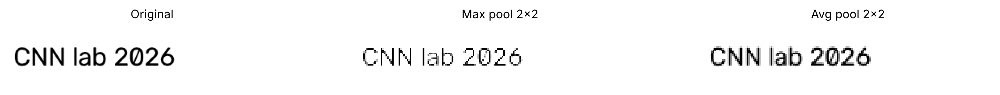

In [ ]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np, cv2
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from scipy.signal import correlate2d
from IPython.display import display

img = np.asarray(Image.open("building.png").convert("L").resize((688, 384), Image.LANCZOS), dtype=float) / 255.0
conv = lambda x, k: correlate2d(x, k, mode="same", boundary="symm")
relu = lambda x: np.maximum(0, x)
def pool(x, kind):
    h, w = (x.shape[0] // 2) * 2, (x.shape[1] // 2) * 2
    b = x[:h, :w].reshape(h // 2, 2, w // 2, 2)
    return b.max(axis=(1, 3)) if kind == "max" else b.mean(axis=(1, 3))

filters = {
    "Horizontal edge": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float),
    "Vertical edge":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float),
    "Sharpen":         np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float),
}
rows = []
for name, k in filters.items():
    B = relu(conv(img, k)); P = B.max(); Cm, Da = pool(B, "max"), pool(B, "avg")
    rows.append({"Filter": name, "Peak after ReLU": P, "Peak max pool": Cm.max(), "Peak avg pool": Da.max(),
                 "Avg peak / Max peak": Da.max() / Cm.max(),
                 "% pixels above half of peak (max)": 100 * (Cm > 0.5 * P).mean(),
                 "% pixels above half of peak (avg)": 100 * (Da > 0.5 * P).mean()})
display(pd.DataFrame(rows).set_index("Filter").round(3))

# --- dark ink on white (white = 255, ink = 0) ---
txt = np.full((80, 360), 255, np.uint8)
cv2.putText(txt, "CNN lab 2026", (8, 52), cv2.FONT_HERSHEY_SIMPLEX, 1.1, 0, 1, cv2.LINE_AA)
t = txt.astype(float); mx, av = pool(t, "max"), pool(t, "avg")
display(pd.DataFrame({"Stroke pixels (value < 200)": [(t < 200).sum(), (mx < 200).sum(), (av < 200).sum()],
                      "Darkest value": [t.min(), mx.min(), av.min()]},
                     index=["Original", "Max pool 2x2", "Avg pool 2x2"]))
fig, ax = plt.subplots(1, 3, figsize=(18, 3))
for a, m, tt in zip(ax, [t, mx, av], ["Original", "Max pool 2x2", "Avg pool 2x2"]):
    a.imshow(m, cmap="gray", vmin=0, vmax=255); a.set_title(tt); a.axis("off")
plt.show()

**Takeaway.** Max pooling keeps the full peak of every thin edge or highlight, average pooling divides it by up to 4 (Sharpen drops from 2.612 to 1.526). For dark ink on white, max pooling picks the white background and erases thin strokes, so average pooling keeps them better (unless the image is inverted first).

## Question 3: Parameter growth and receptive field
**What the cell shows:** the percentage increase from Model A to Model B, the receptive field of stacked 3x3 layers, and the parameter saving of two 3x3 layers against one 5x5 layer.

In [ ]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import display
from tensorflow import keras
from tensorflow.keras import layers

def build(k):
    return keras.Sequential([
        keras.Input((32, 32, 3)),
        layers.Conv2D(5, k, padding="same", activation="relu"), layers.MaxPooling2D(2),
        layers.Conv2D(10, k, padding="same", activation="relu"), layers.MaxPooling2D(2),
        layers.GlobalAveragePooling2D(), layers.Dense(10, activation="softmax")])

a, b = build(3).count_params(), build(5).count_params()
ca, cb = 140 + 460, 380 + 1260
display(pd.DataFrame({"Model A (3x3)": [a, ca], "Model B (5x5)": [b, cb], "Increase": [b - a, cb - ca],
                      "Increase %": [round(100 * (b - a) / a, 2), round(100 * (cb - ca) / ca, 2)]},
                     index=["All trainable parameters", "Conv layers only"]))
print(f"Percentage increase = (1750 - 710) / 710 x 100 = {100 * (b - a) / a:.2f} %")

# receptive field of n stacked 3x3 layers with stride 1: 1 + 2n
display(pd.DataFrame({"Receptive field": [f"{1 + 2*n} x {1 + 2*n}" for n in (1, 2, 3)]}, index=[f"{n} stacked 3x3 layer(s)" for n in (1, 2, 3)]))

# parameters: one 5x5 layer vs two 3x3 layers
def conv_p(k, cin, cout): return (k * k * cin + 1) * cout
rows = []
for label, cin, cout, mid in [("Conv1 (3 to 5 channels)", 3, 5, 3), ("Conv1 (3 to 5 channels)", 3, 5, 5),
                              ("Conv2 (5 to 10 channels)", 5, 10, 5), ("Conv2 (5 to 10 channels)", 5, 10, 10)]:
    p5 = conv_p(5, cin, cout); p33 = conv_p(3, cin, mid) + conv_p(3, mid, cout)
    rows.append({"Layer replaced": label, "Mid channels": mid, "One 5x5": p5, "Two 3x3": p33, "Saved": p5 - p33,
                 "Saved %": round(100 * (p5 - p33) / p5, 1)})
display(pd.DataFrame(rows).set_index("Layer replaced"))

print("Weights only, C channels everywhere: 25 C^2 (one 5x5) vs 18 C^2 (two 3x3) -> saving 7 C^2 = 28 %")
display(pd.DataFrame({"One 5x5": [25*C*C for C in (5, 10, 64)], "Two 3x3": [18*C*C for C in (5, 10, 64)],
                      "Saved": [7*C*C for C in (5, 10, 64)]}, index=[f"C = {C}" for C in (5, 10, 64)]))

,Model A (3x3),Model B (5x5),Increase,Increase %
All trainable parameters,710,1750,1040,146.48
Conv layers only,600,1640,1040,173.33


Percentage increase = (1750 - 710) / 710 x 100 = 146.48 %


,Receptive field
1 stacked 3x3 layer(s),3 x 3
2 stacked 3x3 layer(s),5 x 5
3 stacked 3x3 layer(s),7 x 7


,Mid channels,One 5x5,Two 3x3,Saved,Saved %
Layer replaced,,,,,
Conv1 (3 to 5 channels),3,380,224,156,41.1
Conv1 (3 to 5 channels),5,380,370,10,2.6
Conv2 (5 to 10 channels),5,1260,690,570,45.2
Conv2 (5 to 10 channels),10,1260,1370,-110,-8.7


Weights only, C channels everywhere: 25 C^2 (one 5x5) vs 18 C^2 (two 3x3) -> saving 7 C^2 = 28 %


,One 5x5,Two 3x3,Saved
C = 5,625,450,175
C = 10,2500,1800,700
C = 64,102400,73728,28672


**Takeaway.** The total grows by 1040 parameters (146.48%). Two stacked 3x3 layers cover a 5x5 receptive field and save 28% of the weights when the channel counts are equal. With very few channels and biases included, the saving depends on the middle channel count and can turn negative (Conv2 with 10 middle channels).

## Question 4: Order of ReLU and max pooling
**What the cell shows:** a 2x2 proof patch, a counterexample for average pooling, an exact check on all five real feature maps, and the operation count.

In [ ]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np, time
import pandas as pd
from PIL import Image
from scipy.signal import correlate2d
from IPython.display import display

relu = lambda x: np.maximum(0, x)
def maxpool(x):
    h, w = (x.shape[0] // 2) * 2, (x.shape[1] // 2) * 2
    return x[:h, :w].reshape(h // 2, 2, w // 2, 2).max(axis=(1, 3))
def avgpool(x):
    h, w = (x.shape[0] // 2) * 2, (x.shape[1] // 2) * 2
    return x[:h, :w].reshape(h // 2, 2, w // 2, 2).mean(axis=(1, 3))

# --- 2x2 sample patches ---
rows = []
for label, p in [("Mixed signs [-3, 2; -1, -5]", np.array([[-3.0, 2.0], [-1.0, -5.0]])),
                 ("All negative [-3, -2; -1, -5]", np.array([[-3.0, -2.0], [-1.0, -5.0]]))]:
    a, b = maxpool(relu(p))[0, 0], relu(maxpool(p))[0, 0]
    rows.append({"Patch": label, "ReLU then Max": a, "Max then ReLU": b, "Equal": a == b})
p = np.array([[-3.0, 2.0], [-1.0, -5.0]])
a, b = avgpool(relu(p))[0, 0], relu(avgpool(p))[0, 0]
rows.append({"Patch": "Mixed signs, AVERAGE pooling", "ReLU then Max": a, "Max then ReLU": b, "Equal": a == b})
display(pd.DataFrame(rows).set_index("Patch").rename(columns={"ReLU then Max": "ReLU then Pool", "Max then ReLU": "Pool then ReLU"}))

# --- check on the five real feature maps ---
img = np.asarray(Image.open("building.png").convert("L").resize((688, 384), Image.LANCZOS), dtype=float) / 255.0
ks = {"Horizontal edge": [[-1,-2,-1],[0,0,0],[1,2,1]], "Vertical edge": [[-1,0,1],[-2,0,2],[-1,0,1]],
      "Sharpen": [[0,-1,0],[-1,5,-1],[0,-1,0]], "Gaussian blur": (np.array([[1,2,1],[2,4,2],[1,2,1]]) / 16).tolist(),
      "Emboss": [[-2,-1,0],[-1,1,1],[0,1,2]]}
check = {}
for name, k in ks.items():
    A = correlate2d(img, np.array(k, float), mode="same", boundary="symm")
    check[name] = np.array_equal(maxpool(relu(A)), relu(maxpool(A)))
display(pd.DataFrame({"Outputs identical": check}).rename_axis("Real feature map (max pool)"))

# --- efficiency ---
A = correlate2d(img, np.array(ks["Horizontal edge"], float), mode="same", boundary="symm")
t0 = time.perf_counter()
for _ in range(300): maxpool(relu(A))
t1 = time.perf_counter()
for _ in range(300): relu(maxpool(A))
t2 = time.perf_counter()
display(pd.DataFrame({"ReLU evaluations": [A.size, A.size // 4], "Time for 300 runs (s)": [round(t1 - t0, 3), round(t2 - t1, 3)]},
                     index=["Conv, ReLU, MaxPool", "Conv, MaxPool, ReLU"]))

,ReLU then Pool,Pool then ReLU,Equal
Patch,,,
"Mixed signs [-3, 2; -1, -5]",2.0,2.0,True
"All negative [-3, -2; -1, -5]",0.0,0.0,True
"Mixed signs, AVERAGE pooling",0.5,0.0,False


,Outputs identical
Real feature map (max pool),
Horizontal edge,True
Vertical edge,True
Sharpen,True
Gaussian blur,True
Emboss,True


,ReLU evaluations,Time for 300 runs (s)
"Conv, ReLU, MaxPool",264192,1.206
"Conv, MaxPool, ReLU",66048,1.168


**Takeaway.** For max pooling the two orders always give the same output, because ReLU never reverses the order of two numbers. For average pooling they differ. Pooling first needs 4 times fewer ReLU evaluations. In NumPy the measured time is about the same, because the pooling step itself dominates the cost.

## Question 5: Filter collapse (debugging scenario)
**What the cell shows:** a small training test (horizontal vs vertical stripes, 5 filters, 20 epochs) that reproduces two causes of identical filters and tests one fix.

In [ ]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display
from tensorflow import keras
from tensorflow.keras import layers

def make_data(n=600, size=16, seed=0):
    rng = np.random.default_rng(seed)
    X = np.zeros((n, size, size, 1), np.float32); y = rng.integers(0, 2, n)
    idx = np.arange(size)
    for i in range(n):
        period = rng.integers(3, 6); phase = rng.integers(0, period)
        s = (((idx + phase) // (period // 2 if period >= 4 else 2)) % 2).astype(np.float32)
        X[i, :, :, 0] = s[:, None] if y[i] == 0 else s[None, :]
    return X + rng.normal(0, 0.1, X.shape).astype(np.float32), y

X, y = make_data()

def run(tag, init, lr, leaky=False):
    keras.utils.set_random_seed(1)
    m = keras.Sequential([keras.Input((16, 16, 1)),
        layers.Conv2D(5, 3, padding="same", kernel_initializer=init, bias_initializer="zeros", name="conv1"),
        layers.LeakyReLU(0.1) if leaky else layers.ReLU(),
        layers.GlobalAveragePooling2D(), layers.Dense(2, activation="softmax")])
    m.compile(keras.optimizers.SGD(lr), "sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(X, y, epochs=20, batch_size=32, verbose=0)
    W = m.get_layer("conv1").get_weights()[0].reshape(9, 5).T
    Wn = W / (np.linalg.norm(W, axis=1, keepdims=True) + 1e-12)
    sim = (Wn @ Wn.T)[np.triu_indices(5, 1)].mean()
    pre = np.asarray(keras.Model(m.inputs, m.get_layer("conv1").output)([X[:100]]))
    dead = int(sum(np.maximum(pre[..., k], 0).max() == 0 for k in range(5)))
    return {"Run": tag, "Mean cosine similarity of filters": round(float(sim), 3), "Dead filters": f"{dead} / 5",
            "Accuracy": round(float(m.evaluate(X, y, verbose=0)[1]), 2)}

table = pd.DataFrame([
    run("Cause 1: identical init (all weights 0.1), lr 0.1", keras.initializers.Constant(0.1), 0.1),
    run("Cause 2: learning rate 30, ReLU", "he_normal", 30.0),
    run("Reference: He init, lr 0.1, ReLU", "he_normal", 0.1),
    run("Fix: He init, lr 0.05, Leaky ReLU", "he_normal", 0.05, leaky=True),
]).set_index("Run")
display(table)

,Mean cosine similarity of filters,Dead filters,Accuracy
Run,,,
"Cause 1: identical init (all weights 0.1), lr 0.1",0.948,0 / 5,0.46
"Cause 2: learning rate 30, ReLU",0.852,5 / 5,0.54
"Reference: He init, lr 0.1, ReLU",-0.115,0 / 5,1.00
"Fix: He init, lr 0.05, Leaky ReLU",-0.119,0 / 5,1.00


**Takeaway.** Identical starting weights keep the filters nearly the same (similarity 0.948, accuracy at chance level). A learning rate that is far too high kills every ReLU (5 of 5 filters dead). Random He initialization with a moderate learning rate and Leaky ReLU gives distinct, working filters.